# Partial hedging with block products (thesis §6.1)

**Question.** The main analysis uses an all-or-nothing hourly rule (Proposition 1). Does the accuracy–value gap change when the buyer can hedge *partially*, with the two products that exist on real forward markets?

**Setup**
- Two daily products: **peak** (08:00–19:59, 12 h) and **off-peak** (the other 12 h), 1 MW in every hour.
- The buyer chooses shares z = (z_peak, z_offpeak) ∈ [0, 1]² to minimise ρ_λ = (1 − λ) E[cost] + λ CVaR₁₀%[cost] of the *daily* cost.
- Scenarios: today's block forecast + the block residual (actual − forecast) of each of the previous 90 days — the daily analogue of eq. 3.5, which keeps the dependence between hours of the same day.
- Block forward price: mean realised block price of the previous 90 days × 1.05 (daily analogue of eq. 3.6).
- Solved with the Rockafellar–Uryasev linear program.

**Why interior solutions are possible here.** With one product, CVaR[z f + (1 − z) P] = z f + (1 − z) CVaR[P] is linear in z, so the optimum is at a corner (Proposition 1). With two products, CVaR[(1 − z_p) P_peak + (1 − z_o) P_off] is convex but not linear in z, so the optimum can be interior.

**Compared with the earlier exploratory version** (`continuous_z.ipynb` in the thesis folder, 50 days of NP only): (1) the scenarios used forecast − actual, the mirror of eq. 3.5; (2) the CVaR term of the linear program used 1/((1 − α) S) instead of 1/(α S), i.e. the mean of the worst 90 % of scenarios instead of the worst 10 %; (3) it did not compute regret. This notebook fixes the three and runs the full sample of all five markets.

Helpers: `block_scenarios`, `solve_block_hedge`, `block_hedging` in `decision_utils.py` (tested in `tests/test_decision_utils.py`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from decision_utils import (ALPHA, LAMBDAS, MARKETS, FIG_DIR, PEAK_HOURS, CORNERS, load_market,
                            forward_proxy, compute_regret, dm_test, block_scenarios,
                            solve_block_hedge, block_objective, block_hedging)

FIG_DIR.mkdir(parents=True, exist_ok=True)
print('Peak hours:', PEAK_HOURS)

Peak hours: (8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19)


## Step 1 — Daily scenarios

Check on one day: the scenarios are the block forecast plus past block residuals (actual − forecast), so a past day on which the price came out *above* the forecast produces a *high* scenario.

In [2]:
df_np = load_market('NP')
s = block_scenarios(df_np, 'DNN Ensemble')
i = 0
print(f"{len(s['dates'])} days with 90 days of history; first day {s['dates'][i].date()}")
print(f"Forward price, peak / off-peak block: {s['f'][i, 0]:.1f} / {s['f'][i, 1]:.1f} EUR")
print(f"Realised block cost:                 {s['actual'][i, 0]:.1f} / {s['actual'][i, 1]:.1f} EUR")
print(f"Peak scenarios: min {s['scen'][i, :, 0].min():.1f}, mean {s['scen'][i, :, 0].mean():.1f}, "
      f"max {s['scen'][i, :, 0].max():.1f} EUR")

# sign check: the highest scenario comes from the past day with the largest positive residual
fc = df_np['DNN Ensemble'].values.reshape(-1, 24)
y = df_np['Real price'].values.reshape(-1, 24)
peak = np.isin(np.arange(24), PEAK_HOURS)
res_peak = (y[:90, peak] - fc[:90, peak]).sum(axis=1)
print('Highest scenario from the day with the largest positive residual:',
      np.argmax(s['scen'][i, :, 0]) == np.argmax(res_peak))

638 days with 90 days of history; first day 2017-03-27
Forward price, peak / off-peak block: 409.6 / 372.7 EUR
Realised block cost:                 363.5 / 343.7 EUR
Peak scenarios: min 237.6, mean 361.1, max 475.1 EUR
Highest scenario from the day with the largest positive residual: True


## Step 2 — The linear program

For S equally likely scenarios P_s = (P_s,peak, P_s,off):

  min over z, v, u:  (1 − λ) · mean_s cost_s(z) + λ · ( v + 1/(α S) · Σ_s u_s )
  subject to  u_s ≥ cost_s(z) − v,  u_s ≥ 0,  0 ≤ z_b ≤ 1,

with cost_s(z) = Σ_b z_b f_b + (1 − z_b) P_s,b. At the optimum v is the VaR and the bracket is the CVaR (Rockafellar and Uryasev, 2000). At λ = 0 the objective is linear, so z_b = 1{f_b < E[P_b]}.

Check on a few days: the LP solution is never worse than a 41 × 41 grid over [0, 1]², and the best of the four corners is the binary rule.

In [3]:
grid = np.linspace(0, 1, 41)
worst = 0.0
for i in range(0, 60, 6):
    for lam in (0.3, 0.7, 1.0):
        z, obj = solve_block_hedge(s['f'][i], s['scen'][i], lam)
        best_grid = min(block_objective([a, b], s['f'][i], s['scen'][i], lam) for a in grid for b in grid)
        worst = max(worst, obj - best_grid)
print(f'Largest excess of the LP objective over the grid optimum: {worst:.2e} EUR '
      '(zero up to rounding: the LP is at least as good as the grid)')

i = 0
for lam in (0.0, 0.5, 1.0):
    z, obj = solve_block_hedge(s['f'][i], s['scen'][i], lam)
    corner_obj = [block_objective(c, s['f'][i], s['scen'][i], lam) for c in CORNERS]
    print(f'λ = {lam}: z = ({z[0]:.2f}, {z[1]:.2f}), ρ = {obj:.1f}; best corner {CORNERS[np.argmin(corner_obj)]}, ρ = {min(corner_obj):.1f}')

Largest excess of the LP objective over the grid optimum: 2.27e-13 EUR (zero up to rounding: the LP is at least as good as the grid)
λ = 0.0: z = (0.00, 0.00), ρ = 698.1; best corner [0. 0.], ρ = 698.1
λ = 0.5: z = (0.00, 0.00), ρ = 728.7; best corner [0. 0.], ρ = 728.7
λ = 1.0: z = (0.65, 0.00), ρ = 757.0; best corner [0. 0.], ρ = 759.4


## Step 3 — Full sample, five markets

For every day, market, model and λ: the partial-cover optimum (LP) and the best binary block decision (the best of the four corners). Regret = cost of the decision − cost of the perfect-foresight decision (z_b = 1 if f_b < realised block cost), divided by 24 to be in EUR/MWh like the hourly analysis. About 4 minutes.

In [4]:
block = {}
for market in MARKETS:
    df = load_market(market)
    block[market] = {k: block_hedging(df, f'{k} Ensemble') for k in ('DNN', 'LEAR')}
    print(f'{market}: {block[market]["DNN"]["day"].nunique()} days')

NP: 638 days


PJM: 638 days


BE: 638 days


FR: 638 days


DE: 638 days


In [5]:
# ── Share of days with an interior solution (0 < z_b < 1 for at least one block) ──
interior = pd.DataFrame({(m, k): block[m][k].groupby('lam')['interior'].mean()
                         for m in MARKETS for k in ('DNN', 'LEAR')})
print('Share of days with an interior optimum, by λ (%):\n')
print((100 * interior).round(1).to_string())
print(f'\nLargest share over markets, models and λ: {100 * interior.values.max():.1f} %')

diff = max((block[m][k].groupby('lam')['regret_cont'].mean()
            - block[m][k].groupby('lam')['regret_bin'].mean()).abs().max()
           for m in MARKETS for k in ('DNN', 'LEAR'))
print(f'Largest difference in mean regret, partial vs binary block rule: {diff:.3f} EUR/MWh')

Share of days with an interior optimum, by λ (%):

      NP       PJM        BE        FR        DE     
     DNN LEAR  DNN LEAR  DNN LEAR  DNN LEAR  DNN LEAR
lam                                                  
0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
0.1  0.9  0.6  0.9  0.9  2.2  1.3  0.5  0.0  1.6  0.8
0.2  2.0  1.6  1.3  1.1  3.4  2.5  2.0  1.7  0.9  1.7
0.3  2.7  1.7  1.6  3.6  4.5  2.8  1.9  2.7  1.3  2.2
0.4  1.6  2.0  2.7  5.8  4.5  4.4  3.1  1.9  1.7  2.8
0.5  2.0  3.1  3.4  4.4  5.3  4.2  4.4  3.4  1.9  3.1
0.6  3.4  4.4  3.4  6.4  4.2  4.2  3.4  5.5  2.4  4.2
0.7  3.9  4.9  4.1  5.0  3.4  3.4  4.2  6.6  2.5  4.2
0.8  5.6  6.7  5.3  5.0  2.5  3.9  4.2  5.5  3.1  5.6
0.9  6.3  6.9  5.0  5.6  2.7  3.6  5.6  6.1  4.7  6.1
1.0  6.0  6.7  5.0  6.1  3.8  3.8  6.0  6.7  4.9  6.3

Largest share over markets, models and λ: 6.9 %
Largest difference in mean regret, partial vs binary block rule: 0.051 EUR/MWh


Regret gap LEAR − DNN (EUR/MWh; PJM USD/MWh) and daily DM p-value

            hourly gap  block, binary gap  block, partial gap  hourly p  block, binary p  block, partial p
Market λ                                                                                                  
NP     0.0       0.006              0.036               0.036     0.347            0.015             0.015
       0.5       0.007              0.011               0.014     0.651            0.516             0.382
       1.0       0.038              0.041               0.038     0.102            0.143             0.141
PJM    0.0       0.023              0.016               0.016     0.092            0.487             0.487
       0.5       0.421              0.514               0.522     0.000            0.000             0.000
       1.0       0.348              0.569               0.564     0.001            0.000             0.000
BE     0.0       0.010             -0.008              -0.008     0.734      

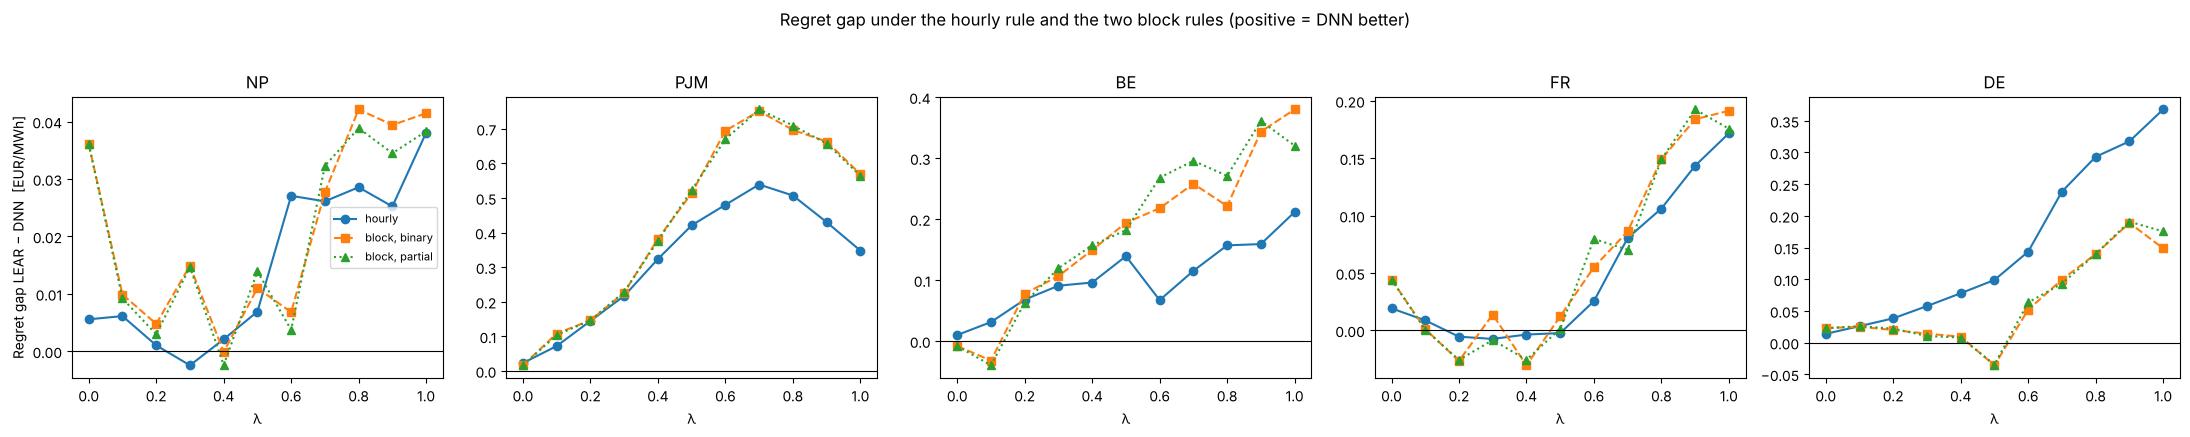

In [6]:
# ── Regret gap (LEAR − DNN) and daily DM p-value: hourly rule vs block rules ──
rows, gaps = [], {}
for market in MARKETS:
    df = load_market(market)
    f = forward_proxy(df['Real price'])
    hourly = {k: compute_regret(df, f'{k} Ensemble', f) for k in ('DNN', 'LEAR')}
    g = {}
    for lam in LAMBDAS:
        col = f'regret_λ={lam:.1f}'
        a = block[market]['LEAR'].query('lam == @lam').set_index('day')
        d = block[market]['DNN'].query('lam == @lam').set_index('day')
        g[lam] = {
            'hourly': (hourly['LEAR'][col].mean() - hourly['DNN'][col].mean(),
                       dm_test(hourly['LEAR'][col], hourly['DNN'][col], hourly['DNN'].index)[1]),
            'block, binary': (a['regret_bin'].mean() - d['regret_bin'].mean(),
                              dm_test(a['regret_bin'], d['regret_bin'], d.index)[1]),
            'block, partial': (a['regret_cont'].mean() - d['regret_cont'].mean(),
                               dm_test(a['regret_cont'], d['regret_cont'], d.index)[1]),
        }
    gaps[market] = g
    for lam in (0.0, 0.5, 1.0):
        rows.append({'Market': market, 'λ': lam,
                     **{f'{rule} gap': g[lam][rule][0] for rule in g[lam]},
                     **{f'{rule} p': g[lam][rule][1] for rule in g[lam]}})
print('Regret gap LEAR − DNN (EUR/MWh; PJM USD/MWh) and daily DM p-value\n')
print(pd.DataFrame(rows).set_index(['Market', 'λ']).round(3).to_string())

fig, axes = plt.subplots(1, 5, figsize=(22, 4.2), sharex=True)
for ax, market in zip(axes, MARKETS):
    for rule, style in [('hourly', '-o'), ('block, binary', '--s'), ('block, partial', ':^')]:
        ax.plot(LAMBDAS, [gaps[market][l][rule][0] for l in LAMBDAS], style, label=rule)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(market)
    ax.set_xlabel('λ')
axes[0].set_ylabel('Regret gap LEAR − DNN  [EUR/MWh]')
axes[0].legend(fontsize=8)
plt.suptitle('Regret gap under the hourly rule and the two block rules (positive = DNN better)', y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / 'block_hedging_gap.png', dpi=150, bbox_inches='tight')
plt.show()

## Interpretation

- **Interior solutions are rare.** In at most 6.9 % of days (any market, model and λ) is the optimal share strictly between 0 and 1 for a block; at λ = 0 never, since the objective is then linear. At least 93 % of optimal decisions stay at a corner.
- **Partial cover barely changes regret.** The mean regret under the partial and the binary block rule differ by at most 0.051 EUR/MWh (BE, LEAR, λ = 0.8; elsewhere less), and the LEAR − DNN gap is of similar size under both rules (λ = 1: NP +0.038 vs +0.041, PJM +0.564 vs +0.569, BE +0.320 vs +0.380, FR +0.176 vs +0.191, DE +0.175 vs +0.149).
- **The move from hourly to daily block products matters more than partial cover.** At λ = 1 the gap is larger under block products in PJM and BE, and smaller in DE (+0.175, p = 0.03, against +0.368 hourly). At λ = 0.5 the DE gap disappears (−0.035, p = 0.24). On NP, the result is the same: no significant gap.
- **The earlier §6.1 figures are not reproduced.** The exploratory run reported 99.8 % of solutions at the boundary and a model gap compressed by 68–99 %; with the corrected scenarios and CVaR term over the full sample, the share at the boundary is 93 % or more and the gap is not compressed by allowing partial cover.